In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option("display.width", 120)

file_path = "Data/Cybercrime_Annexure_Data.xlsx"
state_df = pd.read_excel(file_path,sheet_name="State_UT_Wise")
crime_df = pd.read_excel(file_path,sheet_name="Crime_Head_Wise")

print("State/UT dataset shape:", state_df.shape)
print("Crime head dataset shape:", crime_df.shape)

display(state_df.head())
display(crime_df.head())

State/UT dataset shape: (39, 6)
Crime head dataset shape: (35, 7)


,State/UT,2020,2021,2022,2023,2024
0,Andhra Pradesh,1899,1875,2341,2341,2528
1,Arunachal Pradesh,30,47,14,24,78
2,Assam,3530,4846,1733,909,408
3,Bihar,1512,1413,1621,4450,6380
4,Chhattisgarh,297,352,439,473,660


,Crime Head,Category Group,2020,2021,2022,2023,2024
0,Tampering computer source documents,IT Act,338.0,55.0,65.0,71.0,162
1,Computer Related Offences,IT Act,21926.0,19915.0,23894.0,35329.0,36920
2,Cyber Terrorism,IT Act,26.0,15.0,12.0,11.0,18
3,Publication/transmission of obscene / sexually...,IT Act,6308.0,6598.0,6896.0,7893.0,6990
4,Interception or Monitoring or decryption of In...,IT Act,7.0,2.0,1.0,1.0,4


In [2]:
years = ["2020", "2021", "2022", "2023", "2024"]

summary_labels = [
    "TOTAL STATE(S)",
    "TOTAL UT(S)",
    "TOTAL (ALL INDIA)"
]

regions = state_df[
    ~state_df["State/UT"].isin(summary_labels)
].copy()

# Ensure case counts are numeric
regions[years] = regions[years].apply(
    pd.to_numeric, errors="raise"
)

print("Number of states and UTs:", len(regions))
print("Duplicate region names:", regions["State/UT"].duplicated().sum())
print("\nMissing values:")
display(regions.isna().sum())


Number of states and UTs: 36
Duplicate region names: 0

Missing values:


State/UT    0
2020        0
2021        0
2022        0
2023        0
2024        0
dtype: int64

In [3]:
reported_totals = (
    state_df.loc[
        state_df["State/UT"] == "TOTAL (ALL INDIA)",
        years
    ].iloc[0].astype(int)
)

calculated_totals = regions[years].sum()


validation = pd.DataFrame({
    "Reported Total": reported_totals,
    "Calculated Total": calculated_totals,
    "Difference": calculated_totals - reported_totals
})

display(validation)


,Reported Total,Calculated Total,Difference
2020,50035,50035,0
2021,52974,52974,0
2022,65893,65893,0
2023,86420,86420,0
2024,101928,101928,0


In [4]:
national_trend = regions[years].sum()
trend_df = pd.DataFrame({
    "Year": [int(year) for year in years],
    "Total Cases": national_trend.values
})

trend_df["Change in Cases"] = trend_df["Total Cases"].diff()
trend_df["Year-on-Year Growth (%)"] = (
    trend_df["Total Cases"].pct_change() * 100
)


display(trend_df.round(2).reset_index(drop=True))


,Year,Total Cases,Change in Cases,Year-on-Year Growth (%)
0,2020,50035,NaN,NaN
1,2021,52974,2939.0,5.87
2,2022,65893,12919.0,24.39
3,2023,86420,20527.0,31.15
4,2024,101928,15508.0,17.94


In [5]:

top_10_2024 = (
    regions[["State/UT", "2024"]]
    .sort_values("2024", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_10_2024.index += 1
display(top_10_2024)


,State/UT,2024
1,Telangana,27230
2,Karnataka,21993
3,Uttar Pradesh,11073
4,Maharashtra,9922
5,Bihar,6380
6,Tamil Nadu,5793
7,Kerala,2962
8,Andhra Pradesh,2528
9,Odisha,2501
10,Haryana,1815


In [6]:

state_change = regions[["State/UT", "2020", "2024"]].copy()

state_change["Absolute Change"] = (
    state_change["2024"] - state_change["2020"]
)

state_change["Percentage Change (%)"] = np.where(
    state_change["2020"] != 0,
    (state_change["Absolute Change"] / state_change["2020"]) * 100,
    np.nan
)
largest_increases = state_change.sort_values("Absolute Change", ascending=False).head(10)
display(largest_increases.round(2))


,State/UT,2020,2024,Absolute Change,Percentage Change (%)
23,Telangana,5024,27230,22206,442.00
10,Karnataka,10741,21993,11252,104.76
22,Tamil Nadu,782,5793,5011,640.79
3,Bihar,1512,6380,4868,321.96
13,Maharashtra,5496,9922,4426,80.53
11,Kerala,426,2962,2536,595.31
7,Haryana,656,1815,1159,176.68
0,Andhra Pradesh,1899,2528,629,33.12
18,Odisha,1931,2501,570,29.52
19,Punjab,378,888,510,134.92


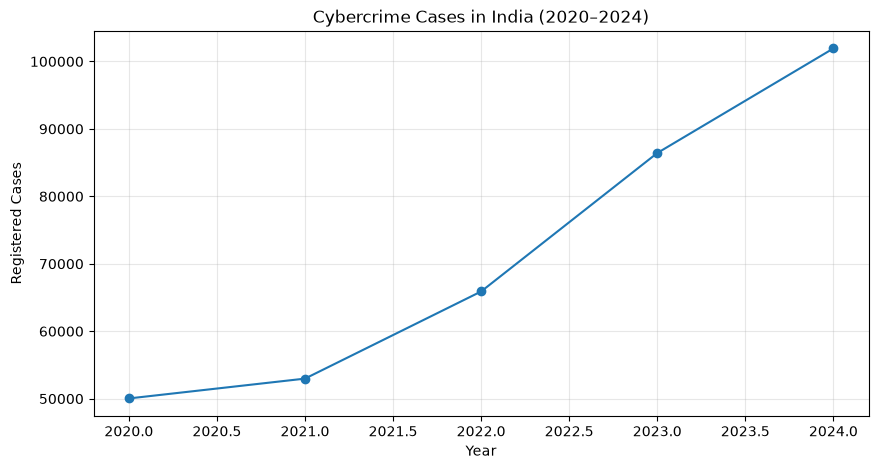

In [7]:

plt.figure(figsize=(10, 5))
plt.plot(trend_df["Year"], trend_df["Total Cases"], marker="o")

plt.title("Cybercrime Cases in India (2020–2024)")
plt.xlabel("Year")
plt.ylabel("Registered Cases")
plt.grid(True, alpha=0.3)

plt.show()


In [8]:

percentage_increases = (
    state_change[state_change["2020"] > 0]
    .sort_values("Percentage Change (%)", ascending=False)
    .head(10)
    [["State/UT", "2020", "2024",
      "Absolute Change", "Percentage Change (%)"]]
    .reset_index(drop=True)
)

display(percentage_increases.round(2))


,State/UT,2020,2024,Absolute Change,Percentage Change (%)
0,Puducherry,10,142,132,1320.00
1,Tamil Nadu,782,5793,5011,640.79
2,Kerala,426,2962,2536,595.31
3,Chandigarh,17,116,99,582.35
4,A&N Islands,5,28,23,460.00
5,Telangana,5024,27230,22206,442.00
6,Bihar,1512,6380,4868,321.96
7,Mizoram,13,50,37,284.62
8,Haryana,656,1815,1159,176.68
9,Arunachal Pradesh,30,78,48,160.00


In [9]:

# Remove summary rows
crime_details = crime_df[
    ~crime_df["Crime Head"].str.startswith("Total", na=False)
].copy()

# Sort by 2024 cases
top_crimes = crime_details.sort_values("2024", ascending=False).head(10)

display(top_crimes[["Crime Head", "Category Group", "2024"]])


,Crime Head,Category Group,2024
1,Computer Related Offences,IT Act,36920
18,Fraud,IPC/BNS,29758
19,Cheating,IPC/BNS,19296
3,Publication/transmission of obscene / sexually...,IT Act,6990
26,Other Offences,IPC/BNS,4109
13,Cyber Stalking/Bullying of Women/Children,IPC/BNS,1240
10,Other Sections of IT Act,IT Act,718
20,Forgery,IPC/BNS,702
24,Cyber Blackmailing/Threatening,IPC/BNS,601
25,Fake News on Social Media,IPC/BNS,483


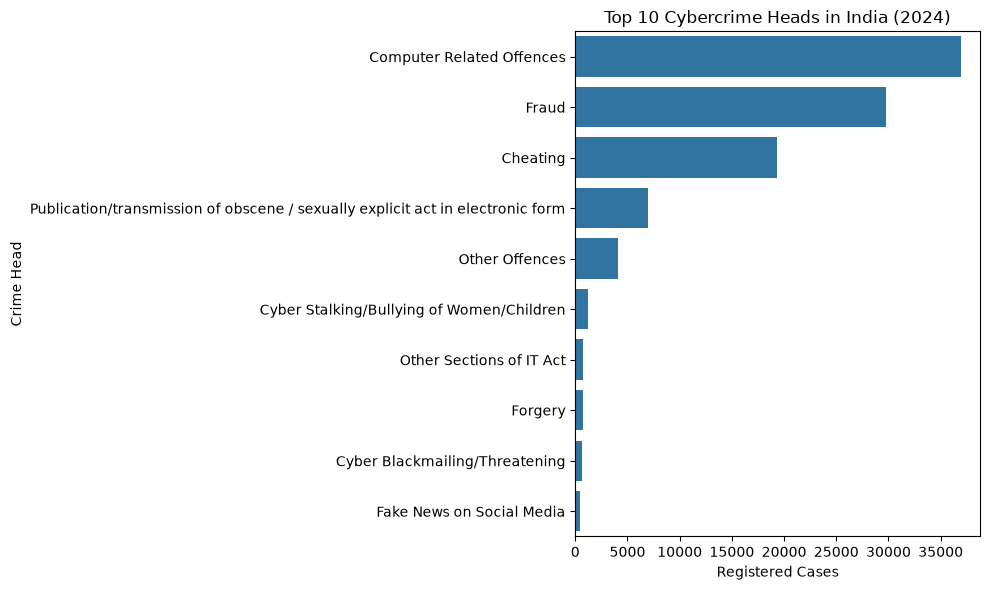

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_crimes,
    x="2024",
    y="Crime Head"
)

plt.title("Top 10 Cybercrime Heads in India (2024)")
plt.xlabel("Registered Cases")
plt.ylabel("Crime Head")
plt.tight_layout()
plt.show()


In [11]:

# Calculate each crime head's percentage of all cases in 2024
top_crimes = top_crimes.copy()

top_crimes["Share (%)"] = (
    top_crimes["2024"] / 101928 * 100)
display(top_crimes[["Crime Head", "2024", "Share (%)"]].round(2))


,Crime Head,2024,Share (%)
1,Computer Related Offences,36920,36.22
18,Fraud,29758,29.20
19,Cheating,19296,18.93
3,Publication/transmission of obscene / sexually...,6990,6.86
26,Other Offences,4109,4.03
13,Cyber Stalking/Bullying of Women/Children,1240,1.22
10,Other Sections of IT Act,718,0.70
20,Forgery,702,0.69
24,Cyber Blackmailing/Threatening,601,0.59
25,Fake News on Social Media,483,0.47


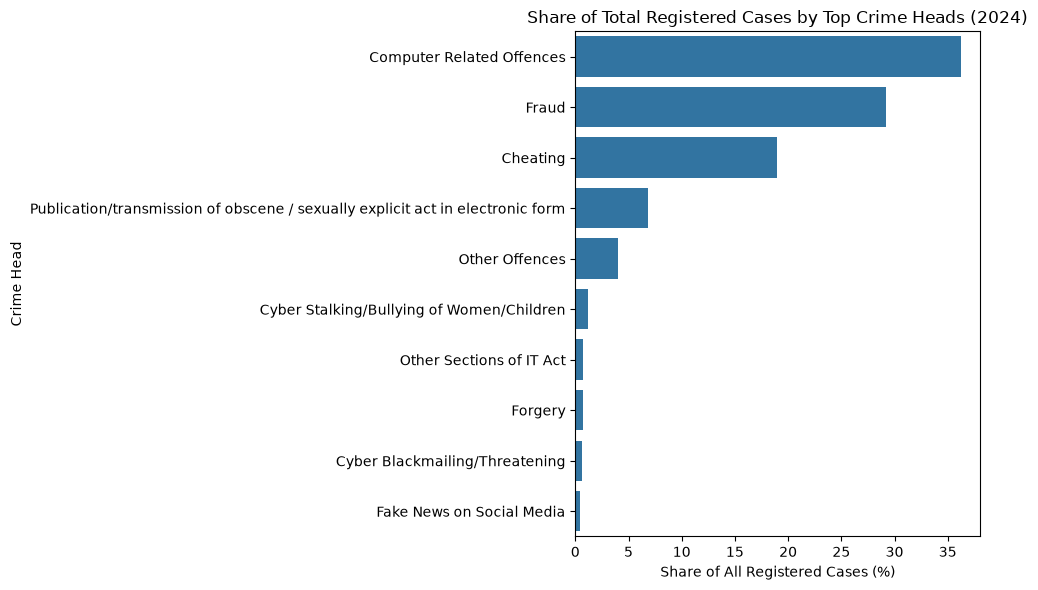

In [12]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_crimes.sort_values("Share (%)", ascending=False),
    x="Share (%)",
    y="Crime Head"
)

plt.title("Share of Total Registered Cases by Top Crime Heads (2024)")
plt.xlabel("Share of All Registered Cases (%)")
plt.ylabel("Crime Head")
plt.tight_layout()
plt.show()


In [13]:
# Keep individual crime heads, excluding summary totals
crime_trends = crime_df[
    ~crime_df["Crime Head"].str.startswith("Total", na=False)
].copy()

crime_trends["Change"] = crime_trends["2024"] - crime_trends["2020"]

crime_trends["Growth (%)"] = (
    crime_trends["Change"]
    / crime_trends["2020"].replace(0, np.nan)
) * 100

# Largest increases by number of cases
top_growth = crime_trends.sort_values(
    "Change", ascending=False
).head(10)

display(
    top_growth[
        ["Crime Head", "2020", "2024", "Change", "Growth (%)"]
    ].round(2)
)


,Crime Head,2020,2024,Change,Growth (%)
18,Fraud,10395.0,29758,19363.0,186.27
1,Computer Related Offences,21926.0,36920,14994.0,68.38
19,Cheating,4480.0,19296,14816.0,330.71
26,Other Offences,2674.0,4109,1435.0,53.66
3,Publication/transmission of obscene / sexually...,6308.0,6990,682.0,10.81
13,Cyber Stalking/Bullying of Women/Children,872.0,1240,368.0,42.20
24,Cyber Blackmailing/Threatening,303.0,601,298.0,98.35
32,Other SLL Crimes,48.0,236,188.0,391.67
20,Forgery,582.0,702,120.0,20.62
22,Fake Profile,149.0,266,117.0,78.52


Calculate changes by crime head :-

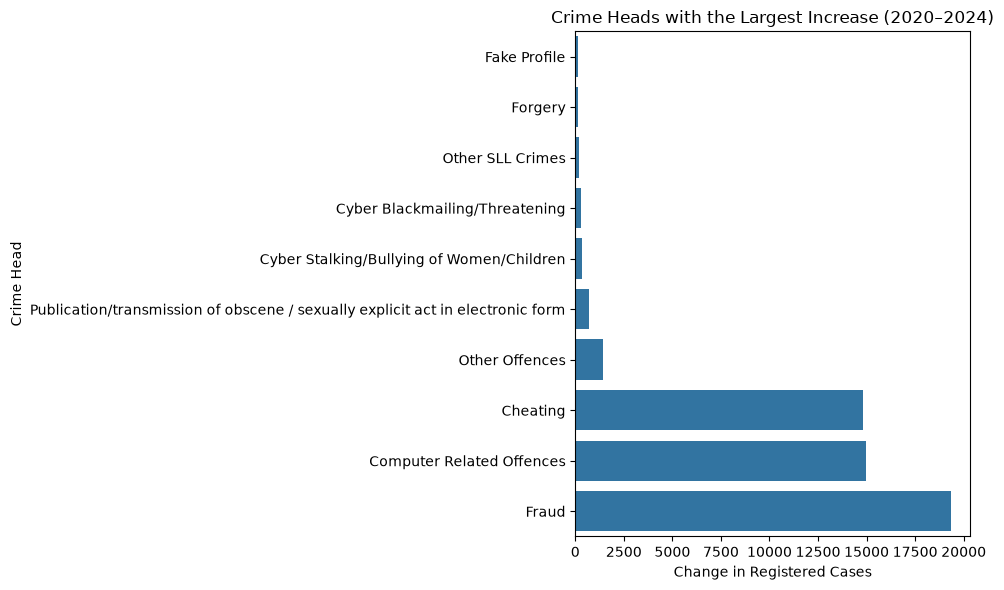

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_growth.sort_values("Change"),
    x="Change",
    y="Crime Head"
)

plt.title("Crime Heads with the Largest Increase (2020–2024)")
plt.xlabel("Change in Registered Cases")
plt.ylabel("Crime Head")
plt.tight_layout()
plt.show()


Find crime heads with the largest decreases:-

In [15]:
# Keep individual crime heads, excluding summary totals
crime_trends = crime_df[
    ~crime_df["Crime Head"].str.startswith("Total", na=False)
].copy()

crime_trends["Change"] = crime_trends["2024"] - crime_trends["2020"]

# Sort from largest decrease to smallest
decreased_crimes = crime_trends.sort_values("Change").head(10)

display(
    decreased_crimes[
        ["Crime Head", "2020", "2024", "Change"]
    ]
)


,Crime Head,2020,2024,Change
10,Other Sections of IT Act,1017.0,718,-299.0
0,Tampering computer source documents,338.0,162,-176.0
25,Fake News on Social Media,578.0,483,-95.0
28,Gambling Act (Online Gambling),63.0,37,-26.0
29,Lotteries Act (Online Lotteries),26.0,0,-26.0
21,Defamation/Morphing,51.0,28,-23.0
30,Copy Right Act,49.0,30,-19.0
17,Data theft,98.0,88,-10.0
2,Cyber Terrorism,26.0,18,-8.0
23,Counterfeiting,9.0,3,-6.0


Plot the national trend by crime head :-

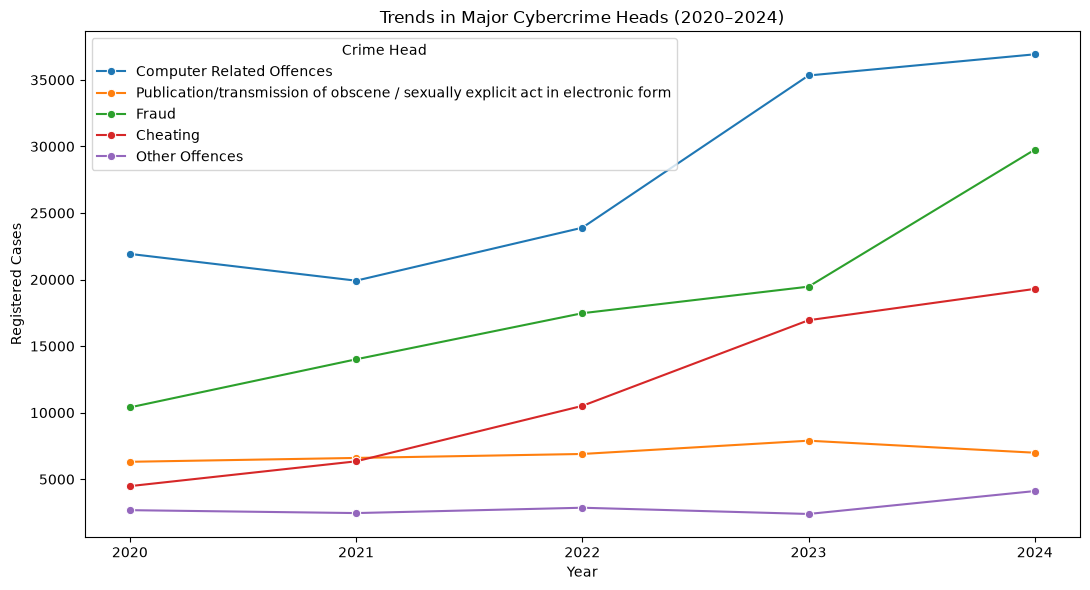

In [16]:
# Select a few major individual crime heads for comparison
selected_heads = [
    "Fraud",
    "Cheating",
    "Computer Related Offences",
    "Other Offences",
    "Publication/transmission of obscene / sexually explicit act in electronic form"
]

crime_yearly = crime_df[
    crime_df["Crime Head"].isin(selected_heads)
].copy()

crime_yearly = crime_yearly.melt(
    id_vars="Crime Head",
    value_vars=years,
    var_name="Year",
    value_name="Cases"
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=crime_yearly,
    x="Year",
    y="Cases",
    hue="Crime Head",
    marker="o"
)

plt.title("Trends in Major Cybercrime Heads (2020–2024)")
plt.xlabel("Year")
plt.ylabel("Registered Cases")
plt.tight_layout()
plt.show()


Compare major crime heads over five years :-

In [17]:
selected_heads = [
    "Fraud",
    "Cheating",
    "Computer Related Offences",
    "Other Offences"
]

major_crimes = crime_df[
    crime_df["Crime Head"].isin(selected_heads)
]

display(major_crimes[["Crime Head"] + years])


,Crime Head,2020,2021,2022,2023,2024
1,Computer Related Offences,21926.0,19915.0,23894.0,35329.0,36920
18,Fraud,10395.0,14007.0,17470.0,19466.0,29758
19,Cheating,4480.0,6343.0,10509.0,16943.0,19296
26,Other Offences,2674.0,2456.0,2857.0,2389.0,4109


Calculate the overall percentage increase :-

In [18]:
total_2020 = int(trend_df.loc[0, "Total Cases"])
total_2024 = int(trend_df.loc[4, "Total Cases"])

absolute_increase = total_2024 - total_2020
percentage_increase = absolute_increase / total_2020 * 100

print("Absolute increase:", absolute_increase)
print("Percentage increase:", round(percentage_increase, 2), "%")


Absolute increase: 51893
Percentage increase: 103.71 %


Heatmap :-

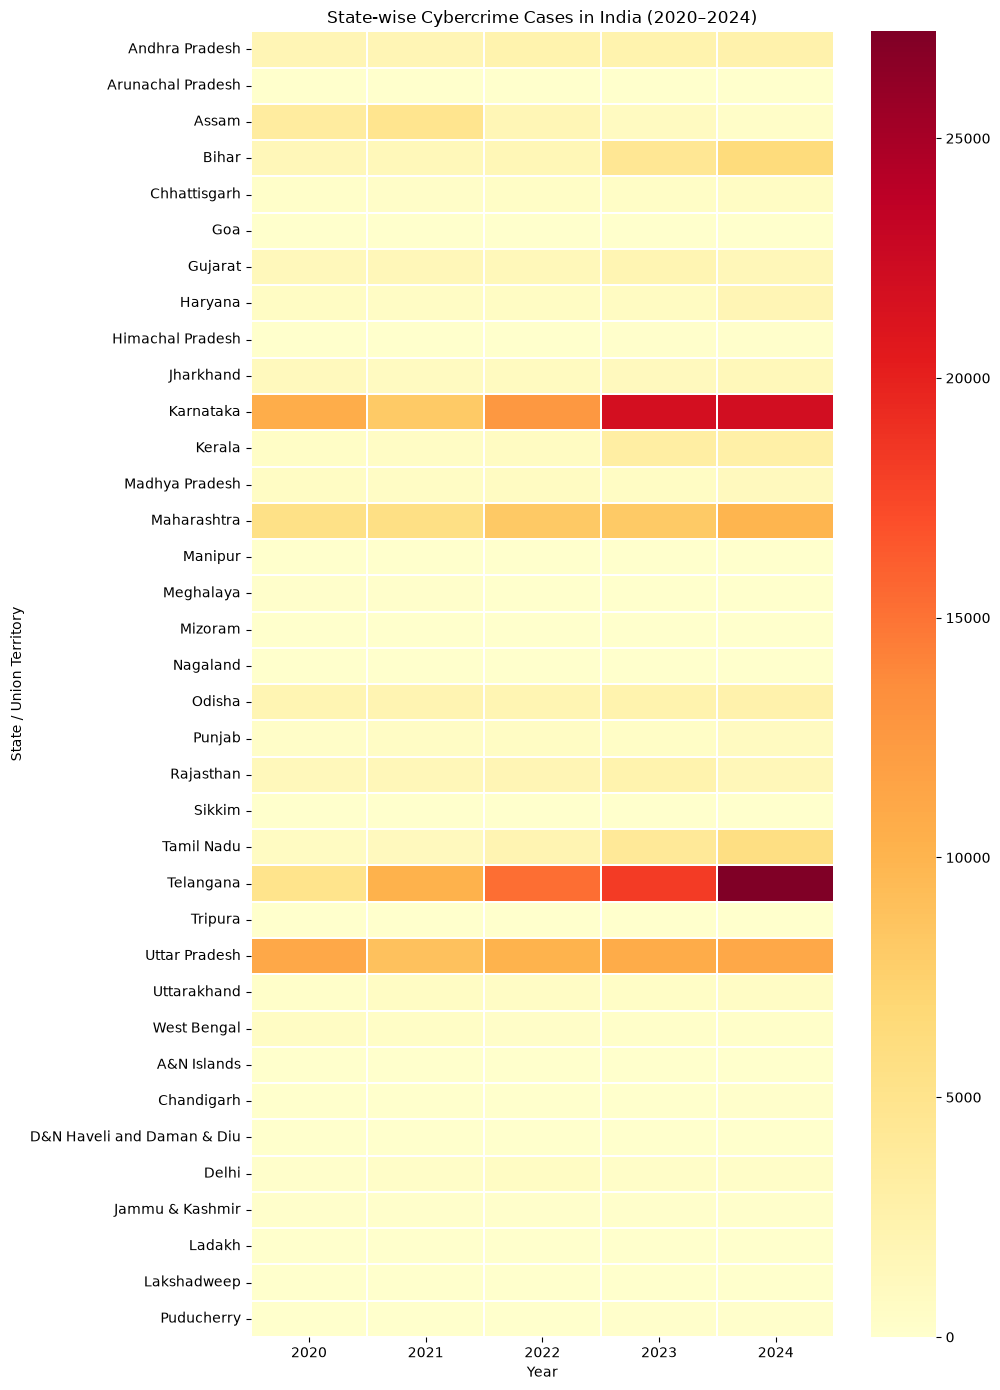

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

years = ["2020", "2021", "2022", "2023", "2024"]
summary_rows = ["TOTAL STATE(S)", "TOTAL UT(S)", "TOTAL (ALL INDIA)"]
heatmap_df = state_df[~state_df["State/UT"].isin(summary_rows)].copy()
heatmap_data = heatmap_df.set_index("State/UT")[years]

plt.figure(figsize=(10, 14))
sns.heatmap(heatmap_data, cmap="YlOrRd", linewidths=0.3)

plt.title("State-wise Cybercrime Cases in India (2020–2024)")
plt.xlabel("Year")
plt.ylabel("State / Union Territory")
plt.tight_layout()
plt.show()
